# Test d'une image avec votre modèle YOLO — Blocs séparés & Résultat visuel final

Ce notebook est organisé en **blocs séparés** pour charger votre modèle YOLO, tester **une image**, lancer l'analyse et **afficher clairement le résultat final** (visuel + tableau des détections/métriques) :
- **Bloc 1** : imports et chemin de votre modèle (`best.pt`) + chemin de l'image à tester.
- **Bloc 2** : chargement du modèle YOLO et vérification de l'image.
- **Bloc 3** : exécution de la prédiction sur l'image (détection et/ou segmentation + extraction des mesures géométriques si des masques sont présents).
- **Bloc 4 — Résultat final** : affichage visuel complet du résultat (image annotée + tableau récapitulatif + sauvegarde optionnelle).

## Bloc 1 — Chemin du modèle YOLO et de l'image à tester

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.morphology import skeletonize
from ultralytics import YOLO

# 1. Chemin vers votre modèle entraîné (best.pt)
MODEL_PATH = Path(r"D:\S5\Projet_d_expertise\projet\models\wiring_harness_connectors_seg\weights\best.pt").resolve()

# 2. Chemin vers l'image que vous voulez tester
IMAGE_PATH = Path(r"D:\S5\Projet_d_expertise\projet\data\processed\Harness comportement detection.v1i.yolov8\test\images\Cable_MHEV_NC11_2_jpg.rf.32eca55c054dabaed70b5ec34c4bb346.jpg").resolve()

# Seuils d'inférence
CONF_THRESHOLD = 0.25
IMG_SIZE = 640

print("Paramètres définis :")
print("  - Modèle :", MODEL_PATH)
print("  - Image  :", IMAGE_PATH)

c:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
c:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
c:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


Paramètres définis :
  - Modèle : D:\S5\Projet_d_expertise\projet\models\wiring_harness_connectors_seg\weights\best.pt
  - Image  : D:\S5\Projet_d_expertise\projet\data\processed\Harness comportement detection.v1i.yolov8\test\images\Cable_MHEV_NC11_2_jpg.rf.32eca55c054dabaed70b5ec34c4bb346.jpg


## Bloc 2 — Chargement du modèle YOLO et préparation de l'image

In [2]:
# Recherche automatique du dernier best.pt si le chemin par défaut n'existe pas
if not MODEL_PATH.exists():
    found_weights = sorted(
        Path(r"D:\S5\Projet_d_expertise\projet\models/harness_cable_segmentation").glob("**/best.pt"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if found_weights:
        MODEL_PATH = found_weights[0].resolve()
        print(f"Modèle trouvé automatiquement : {MODEL_PATH}")
    else:
        raise FileNotFoundError(f"Modèle introuvable : {MODEL_PATH}")

# Si IMAGE_PATH est un dossier, on prend la première image disponible
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
if IMAGE_PATH.is_dir():
    imgs = sorted([p for p in IMAGE_PATH.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS])
    if not imgs:
        raise FileNotFoundError(f"Aucune image trouvée dans : {IMAGE_PATH}")
    IMAGE_PATH = imgs[0].resolve()
    print(f"Dossier détecté -> image sélectionnée : {IMAGE_PATH}")

if not IMAGE_PATH.exists():
    raise FileNotFoundError(f"Image introuvable : {IMAGE_PATH}")

img_bgr = cv2.imread(str(IMAGE_PATH))
if img_bgr is None:
    raise ValueError(f"Impossible de lire l'image : {IMAGE_PATH}")

model = YOLO(str(MODEL_PATH))
h, w = img_bgr.shape[:2]
print(f"Modèle chargé avec succès | Classes : {model.names}")
print(f"Image chargée : {IMAGE_PATH.name} ({w}x{h} px)")

Modèle trouvé automatiquement : D:\S5\Projet_d_expertise\projet\models\harness_cable_segmentation\weights\best.pt
Modèle chargé avec succès | Classes : {0: 'cable', 1: 'cable-tie', 2: 'clip', 3: 'connector', 4: 'label'}
Image chargée : Cable_MHEV_NC11_2_jpg.rf.32eca55c054dabaed70b5ec34c4bb346.jpg (640x640 px)


## Bloc 3 — Exécution du test sur l'image et calcul des mesures

In [3]:
def cluster_pts(pts_xy: list[tuple[int, int]], min_dist: float = 8.0) -> list[tuple[int, int]]:
    clusters = []
    for x, y in pts_xy:
        merged = False
        for c in clusters:
            cx, cy, n = c
            if np.hypot(x - cx / n, y - cy / n) <= min_dist:
                c[0] += x
                c[1] += y
                c[2] += 1
                merged = True
                break
        if not merged:
            clusters.append([float(x), float(y), 1])
    return [(int(round(cx / n)), int(round(cy / n))) for cx, cy, n in clusters]

res = model.predict(source=str(IMAGE_PATH), conf=CONF_THRESHOLD, imgsz=IMG_SIZE, verbose=False)[0]

results_rows = []
geometry_overlays = []
neighbor_kernel = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=np.uint8)

if res.boxes is not None and len(res.boxes) > 0:
    cls_ids = res.boxes.cls.cpu().numpy().astype(int)
    confs = res.boxes.conf.cpu().numpy()
    boxes_xyxy = res.boxes.xyxy.cpu().numpy()
    masks_np = res.masks.data.cpu().numpy() if res.masks is not None else None

    for idx in range(len(cls_ids)):
        cid = int(cls_ids[idx])
        cname = model.names.get(cid, str(cid))
        score = round(float(confs[idx]), 3)
        x1, y1, x2, y2 = [round(float(v), 1) for v in boxes_xyxy[idx]]

        length_px = 0
        nb_end = 0
        nb_br = 0

        if masks_np is not None and idx < len(masks_np):
            mask_u8 = cv2.resize(
                (masks_np[idx] > 0.5).astype(np.uint8) * 255,
                (w, h),
                interpolation=cv2.INTER_NEAREST,
            )
            if int((mask_u8 > 0).sum()) > 0:
                closed = cv2.morphologyEx(mask_u8, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
                skel = skeletonize(closed > 0).astype(np.uint8)
                coords_yx = np.argwhere(skel > 0)
                length_px = int(len(coords_yx))

                if length_px > 0:
                    neigh = cv2.filter2D(skel, ddepth=cv2.CV_16S, kernel=neighbor_kernel)
                    active_n = neigh[skel > 0]
                    endpoints = cluster_pts([(int(x), int(y)) for y, x in coords_yx[active_n == 1]], 8.0)
                    branches = cluster_pts([(int(x), int(y)) for y, x in coords_yx[active_n >= 3]], 8.0)
                    nb_end = len(endpoints)
                    nb_br = len(branches)
                    geometry_overlays.append((skel, endpoints, branches))

        results_rows.append({
            "id": idx,
            "classe": cname,
            "confiance": score,
            "bbox_xyxy": [x1, y1, x2, y2],
            "longueur_px": length_px,
            "extremites": nb_end,
            "intersections": nb_br,
        })

df_resultats = pd.DataFrame(results_rows)
print(f"Test terminé : {len(results_rows)} objet(s) détecté(s).")

Test terminé : 9 objet(s) détecté(s).


## Bloc 4 — Résultat final (Visualisation + Tableau récapitulatif)

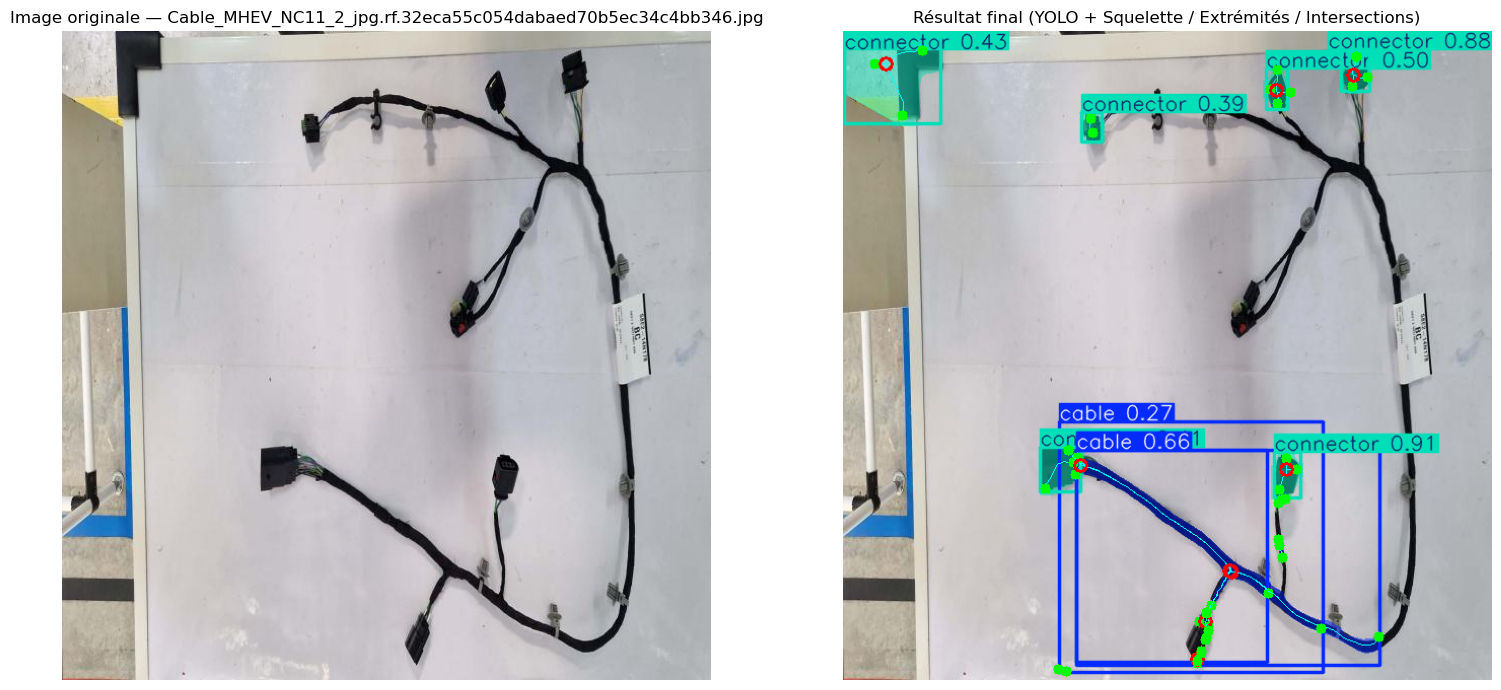

,id,classe,confiance,bbox_xyxy,longueur_px,extremites,intersections
0,0,connector,0.907,"[425.3, 415.4, 451.0, 460.0]",42,3,1
1,1,connector,0.881,"[491.0, 19.0, 519.6, 59.8]",44,3,1
2,2,cable,0.662,"[230.6, 413.8, 418.8, 622.1]",264,8,1
3,3,connector,0.497,"[418.0, 37.5, 438.4, 77.8]",53,4,1
4,4,connector,0.428,"[1.9, 0.0, 96.9, 92.0]",99,3,1
5,5,cable,0.415,"[230.1, 413.2, 529.3, 625.4]",415,8,3
6,6,connector,0.409,"[195.0, 410.5, 234.3, 454.0]",41,2,0
7,7,connector,0.391,"[236.0, 80.1, 255.3, 109.1]",17,2,0
8,8,cable,0.270,"[213.0, 385.5, 473.5, 632.2]",351,12,2


Image résultat enregistrée ici : D:\S5\Projet_d_expertise\projet\src\resultat_Cable_MHEV_NC11_2_jpg.rf.32eca55c054dabaed70b5ec34c4bb346.png


In [4]:
# 1. Préparation de l'image résultat
annotated_yolo = res.plot()  # Détections / masques YOLO

final_vis = annotated_yolo.copy()
for skel, endpoints, branches in geometry_overlays:
    final_vis[skel > 0] = (255, 255, 0)  # Squelette en cyan
    for ex, ey in endpoints:
        cv2.circle(final_vis, (ex, ey), 5, (0, 255, 0), -1)  # Extrémités en vert
    for bx, by in branches:
        cv2.circle(final_vis, (bx, by), 6, (0, 0, 255), 2)  # Intersections en rouge

# 2. Affichage côte à côte : Image originale vs Résultat final
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Image originale — {IMAGE_PATH.name}")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(final_vis, cv2.COLOR_BGR2RGB))
axes[1].set_title("Résultat final (YOLO + Squelette / Extrémités / Intersections)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# 3. Affichage du tableau récapitulatif des résultats
if not df_resultats.empty:
    display(df_resultats)
else:
    print("Aucun objet détecté avec le seuil actuel. Essayez de baisser CONF_THRESHOLD (ex. 0.15).")

# 4. Sauvegarde de l'image résultat à côté de l'notebook
OUTPUT_IMG = Path(f"resultat_{IMAGE_PATH.stem}.png").resolve()
cv2.imwrite(str(OUTPUT_IMG), final_vis)
print(f"Image résultat enregistrée ici : {OUTPUT_IMG}")